In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device :', device)

Device : cpu


In [9]:
import os
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

# --- Chemins ---
BASE_DIR   = '/content/drive/MyDrive/projet_conso'
FINAL_PATH = f'{BASE_DIR}/data/processed/dataset_hourly.parquet'

# Vérification que le fichier existe bien
assert os.path.exists(FINAL_PATH), f'Fichier introuvable : {FINAL_PATH}'

df = pd.read_parquet(FINAL_PATH)
print(f'Dataset chargé : {df.shape[0]:,} lignes × {df.shape[1]} colonnes')
print(f'Période : {df.index.min()} → {df.index.max()}')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset chargé : 34,587 lignes × 15 colonnes
Période : 2006-12-16 18:00:00 → 2010-11-26 20:00:00


,global_active_power,global_reactive_power,voltage,global_intensity,sub_1_kitchen,sub_2_laundry,sub_3_heater_ac,unmetered_wh,hour,day_of_week,month,is_weekend,is_holiday,apparent_temperature,is_imputed
datetime,,,,,,,,,,,,,,,
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,2217.200000,18,5,12,1,0,3.7,0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,2313.233333,19,5,12,1,0,3.3,0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,2261.566667,20,5,12,1,0,3.2,0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,1998.466667,21,5,12,1,0,3.2,0
2006-12-16 22:00:00,2.200133,0.056167,238.760000,9.523333,0.0,8.0,266.0,1926.133333,22,5,12,1,0,2.6,0


In [11]:
import torch
from sklearn.preprocessing import StandardScaler

# --- Reproductibilité ---
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Paramètres du problème ---
TARGET   = 'global_active_power'
HORIZON  = 24  # on prédit les 24 prochaines heures
LOOKBACK = 48   # on regarde les 48 dernières heures (on testera 24 / 168 plus tard)

df = pd.read_parquet(FINAL_PATH)

# 1) Encodage cyclique : 23h et 0h deviennent proches
def add_cyclic(df):
    df = df.copy()
    for col, period in [('hour', 24), ('day_of_week', 7), ('month', 12)]:
        df[f'{col}_sin'] = np.sin(2 * np.pi * df[col] / period)
        df[f'{col}_cos'] = np.cos(2 * np.pi * df[col] / period)
    return df.drop(columns=['hour', 'day_of_week', 'month'])

df = add_cyclic(df)
FEATURES = [TARGET] + [c for c in df.columns if c not in (TARGET, 'is_imputed')]

# 2) Split temporel (jamais de mélange !)
train_df = df.loc[:'2008-12-31']
val_df   = df.loc['2009-01-01':'2009-12-31']
test_df  = df.loc['2010-01-01':]

# 3) Normalisation : apprise sur le TRAIN uniquement
x_scaler = StandardScaler().fit(train_df[FEATURES])
y_scaler = StandardScaler().fit(train_df[[TARGET]])   # pour dé-normaliser les prédictions

def scale(part):
    X = x_scaler.transform(part[FEATURES]).astype('float32')
    y = y_scaler.transform(part[[TARGET]]).ravel().astype('float32')
    return X, y, part['is_imputed'].values

# 4) Fenêtrage : X = L heures passées, y = 24 heures futures
def make_windows(X, y, imputed, lookback=LOOKBACK, horizon=HORIZON):
    Xs, ys, imp = [], [], []
    for t in range(lookback, len(X) - horizon + 1):
        Xs.append(X[t - lookback:t])
        ys.append(y[t:t + horizon])
        imp.append(imputed[t:t + horizon].any())   # cible contenant des heures imputées ?
    return np.array(Xs), np.array(ys), np.array(imp)

X_train, y_train, imp_train = make_windows(*scale(train_df))
X_val,   y_val,   imp_val   = make_windows(*scale(val_df))
X_test,  y_test,  imp_test  = make_windows(*scale(test_df))

print(f'Features ({len(FEATURES)}) : {FEATURES}')
print(f'Train : X {X_train.shape}  y {y_train.shape}')
print(f'Val   : X {X_val.shape}  y {y_val.shape}')
print(f'Test  : X {X_test.shape}  y {y_test.shape}  '
      f'(fenêtres avec cible imputée : {imp_test.sum()})')
def to_cnn(X):
    return torch.tensor(X).permute(0, 2, 1)
n_features = X_train.shape[2]
print(f'Entrée CNN : {tuple(to_cnn(X_train).shape)}')

Features (17) : ['global_active_power', 'global_reactive_power', 'voltage', 'global_intensity', 'sub_1_kitchen', 'sub_2_laundry', 'sub_3_heater_ac', 'unmetered_wh', 'is_weekend', 'is_holiday', 'apparent_temperature', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos']
Train : X (17839, 48, 17)  y (17839, 24)
Val   : X (8689, 48, 17)  y (8689, 24)
Test  : X (7846, 48, 17)  y (7846, 24)  (fenêtres avec cible imputée : 386)
Entrée CNN : (17839, 17, 48)


In [12]:
def predict(model, loader):
    """Renvoie les prédictions du modèle."""
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).cpu().numpy())
    return np.concatenate(preds)

def to_kw(y):
    """Remet les valeurs en kW."""
    return y_scaler.inverse_transform(y.reshape(-1, 1)).reshape(y.shape)

def metrics(y_true, y_pred):
    """Calcule MAE, RMSE, MAPE et WAPE."""
    err = y_pred - y_true
    return {
        'MAE (kW)':  np.abs(err).mean(),
        'RMSE (kW)': np.sqrt((err ** 2).mean()),
        'MAPE (%)':  (np.abs(err) / y_true).mean() * 100,
        'WAPE (%)':  np.abs(err).sum() / y_true.sum() * 100,
    }

In [14]:
def train_model(model, train_loader, val_loader, lr=1e-3, optimizer_name='adam',
                n_epochs=100, patience=10, weight_decay=0.0):
    """Descente de gradient avec early stopping sur la loss de validation."""
    loss_fn = nn.MSELoss()
    if optimizer_name == 'sgd':
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {'train': [], 'val': []}
    best_val, best_state, wait = float('inf'), None, 0
    for epoch in range(n_epochs):
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()              # 1. remise à zéro des gradients
            loss = loss_fn(model(xb), yb)      # 2-3. prédiction + erreur (MSE)
            loss.backward()                    # 4. rétropropagation
            optimizer.step()                   # 5. mise à jour des poids
            train_loss += loss.item() * len(xb)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                val_loss += loss_fn(model(xb), yb).item() * len(xb)
        val_loss /= len(val_loader.dataset)

        history['train'].append(train_loss)
        history['val'].append(val_loss)
        print(f'Epoch {epoch+1:3d} | train {train_loss:.4f} | val {val_loss:.4f}')

        if val_loss < best_val:
            best_val, wait = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f"Arrêt anticipé à l'epoch {epoch+1}")
                break
    model.load_state_dict(best_state)
    return model, history

In [15]:
class CNN1D(nn.Module):
    """CNN 1D : des filtres glissent le long du temps -> 24 prédictions."""
    def __init__(self, n_features, lookback, horizon=24, channels=32, kernel=3, dropout=0.3):
        super().__init__()
        # Partie convolution : détecte des motifs dans la séquence
        self.conv = nn.Sequential(
            nn.Conv1d(n_features, channels, kernel, padding=kernel // 2), nn.ReLU(),
            nn.Conv1d(channels, channels, kernel, padding=kernel // 2), nn.ReLU(),
            nn.MaxPool1d(2),                       # longueur divisée par 2
            nn.Conv1d(channels, 2 * channels, kernel, padding=kernel // 2), nn.ReLU(),
            nn.MaxPool1d(2),                       # longueur encore divisée par 2
        )
        # Partie décision : transforme les motifs en 24 prédictions
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(2 * channels * (lookback // 4), 64), nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        return self.head(self.conv(x))

In [16]:
HORIZON = 24

In [17]:
# Fenêtres pour une longueur d'historique donnée (calculées une seule fois)
_cnn_cache = {}
def get_cnn_data(lookback):
    if lookback not in _cnn_cache:
        Xtr, ytr, _      = make_windows(*scale(train_df), lookback=lookback)
        Xva, yva, _      = make_windows(*scale(val_df),   lookback=lookback)
        Xte, yte, imp_te = make_windows(*scale(test_df),  lookback=lookback)
        _cnn_cache[lookback] = dict(
            train=TensorDataset(to_cnn(Xtr), torch.tensor(ytr)),
            val=TensorDataset(to_cnn(Xva), torch.tensor(yva)),
            test=TensorDataset(to_cnn(Xte), torch.tensor(yte)),
            X_test=Xte, y_test=yte, imp_test=imp_te)
    return _cnn_cache[lookback]

# Configuration de référence : chaque étude ne change qu'UN paramètre
REF_CNN = dict(lookback=48, channels=32, kernel=3, dropout=0.3,
               lr=1e-4, optimizer='adam', batch_size=64, weight_decay=1e-4)

def run_cnn_experiment(label, **changes):
    """Entraîne un CNN avec la config de référence + les changements donnés."""
    cfg = {**REF_CNN, **changes}
    data = get_cnn_data(cfg['lookback'])
    torch.manual_seed(SEED)
    tr = DataLoader(data['train'], batch_size=cfg['batch_size'], shuffle=True)
    va = DataLoader(data['val'],   batch_size=64)
    m = CNN1D(n_features, lookback=cfg['lookback'], channels=cfg['channels'],
              kernel=cfg['kernel'], dropout=cfg['dropout']).to(device)
    print(f'\n=== {label} ===')
    _, h = train_model(m, tr, va, lr=cfg['lr'], optimizer_name=cfg['optimizer'],
                       weight_decay=cfg['weight_decay'], patience=15, n_epochs=60)
    return label, h

def plot_experiments(results, title):
    """Superpose les courbes de validation de plusieurs essais."""
    plt.figure(figsize=(9, 4))
    for label, h in results:
        plt.plot(h['val'], label=f"{label} (min {min(h['val']):.3f})")
    plt.xlabel('Epoch'); plt.ylabel('MSE validation'); plt.legend()
    plt.title(title); plt.show()


=== 24 h ===
Epoch   1 | train 0.9098 | val 0.5753
Epoch   2 | train 0.6965 | val 0.4920
Epoch   3 | train 0.6530 | val 0.4843
Epoch   4 | train 0.6309 | val 0.4796
Epoch   5 | train 0.6151 | val 0.4728
Epoch   6 | train 0.6033 | val 0.4656
Epoch   7 | train 0.5923 | val 0.4633
Epoch   8 | train 0.5836 | val 0.4650
Epoch   9 | train 0.5750 | val 0.4615
Epoch  10 | train 0.5676 | val 0.4660
Epoch  11 | train 0.5616 | val 0.4602
Epoch  12 | train 0.5545 | val 0.4595
Epoch  13 | train 0.5501 | val 0.4636
Epoch  14 | train 0.5448 | val 0.4591
Epoch  15 | train 0.5400 | val 0.4686
Epoch  16 | train 0.5373 | val 0.4661
Epoch  17 | train 0.5332 | val 0.4707
Epoch  18 | train 0.5290 | val 0.4777
Epoch  19 | train 0.5259 | val 0.4664
Epoch  20 | train 0.5226 | val 0.4727
Epoch  21 | train 0.5198 | val 0.4740
Epoch  22 | train 0.5160 | val 0.4668
Epoch  23 | train 0.5119 | val 0.4691
Epoch  24 | train 0.5101 | val 0.4690
Epoch  25 | train 0.5063 | val 0.4742
Epoch  26 | train 0.5031 | val 0.475

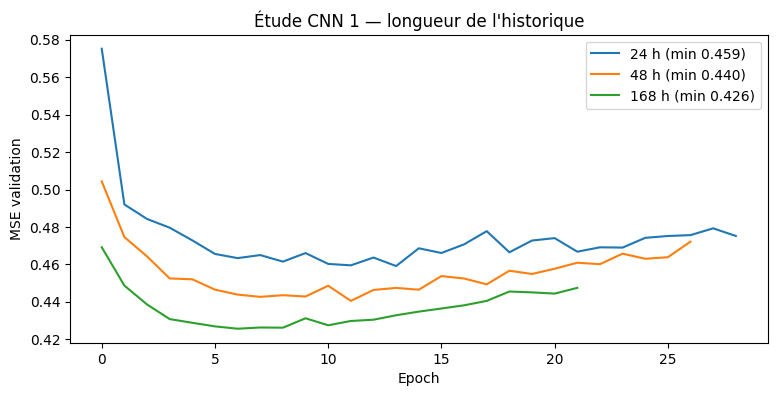

In [22]:
# Étude CNN 1 — Longueur de l'historique
exp_cnn_lookback = [run_cnn_experiment(f'{L} h', lookback=L) for L in [24, 48, 168]]
plot_experiments(exp_cnn_lookback, "Étude CNN 1 — longueur de l'historique")

Plus le CNN voit loin, meilleur il est. Les trois courbes sont bien séparées, et 168 h est en dessous à toutes les epochs.
À 168 h, le CNN passe sous le meilleur score du MLP (0,426 contre 0,437). C’est exactement ce que tu voulais montrer : le CNN exploite la semaine, le MLP non.


=== filtres = 16 ===
Epoch   1 | train 0.9133 | val 0.5919
Epoch   2 | train 0.6997 | val 0.4893
Epoch   3 | train 0.6559 | val 0.4756
Epoch   4 | train 0.6390 | val 0.4686
Epoch   5 | train 0.6271 | val 0.4664
Epoch   6 | train 0.6175 | val 0.4633
Epoch   7 | train 0.6076 | val 0.4594
Epoch   8 | train 0.5993 | val 0.4569
Epoch   9 | train 0.5917 | val 0.4540
Epoch  10 | train 0.5846 | val 0.4521
Epoch  11 | train 0.5795 | val 0.4503
Epoch  12 | train 0.5743 | val 0.4483
Epoch  13 | train 0.5694 | val 0.4503
Epoch  14 | train 0.5649 | val 0.4486
Epoch  15 | train 0.5617 | val 0.4558
Epoch  16 | train 0.5592 | val 0.4481
Epoch  17 | train 0.5552 | val 0.4536
Epoch  18 | train 0.5526 | val 0.4541
Epoch  19 | train 0.5497 | val 0.4531
Epoch  20 | train 0.5465 | val 0.4511
Epoch  21 | train 0.5452 | val 0.4539
Epoch  22 | train 0.5424 | val 0.4540
Epoch  23 | train 0.5406 | val 0.4652
Epoch  24 | train 0.5375 | val 0.4564
Epoch  25 | train 0.5355 | val 0.4607
Epoch  26 | train 0.5341 | v

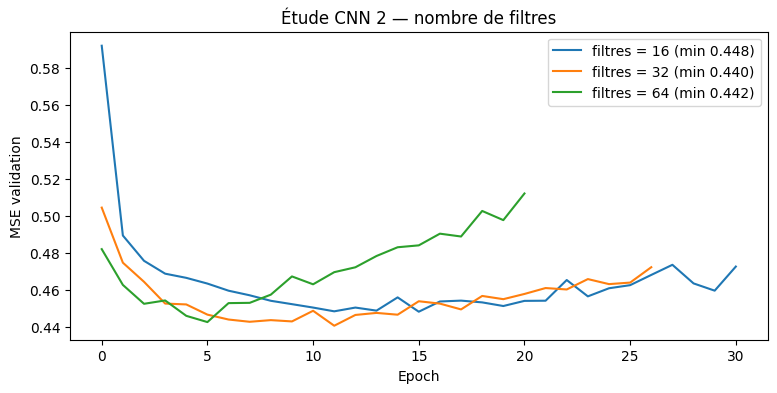

In [23]:
# Étude CNN 2 — Nombre de filtres
exp_cnn_channels = [run_cnn_experiment(f'filtres = {c}', channels=c) for c in [16, 32, 64]]
plot_experiments(exp_cnn_channels, 'Étude CNN 2 — nombre de filtres')


=== noyau = 3 h ===
Epoch   1 | train 0.8584 | val 0.5044
Epoch   2 | train 0.6646 | val 0.4746
Epoch   3 | train 0.6352 | val 0.4642
Epoch   4 | train 0.6150 | val 0.4525
Epoch   5 | train 0.5999 | val 0.4520
Epoch   6 | train 0.5874 | val 0.4465
Epoch   7 | train 0.5765 | val 0.4438
Epoch   8 | train 0.5673 | val 0.4426
Epoch   9 | train 0.5601 | val 0.4435
Epoch  10 | train 0.5529 | val 0.4428
Epoch  11 | train 0.5483 | val 0.4486
Epoch  12 | train 0.5427 | val 0.4405
Epoch  13 | train 0.5379 | val 0.4463
Epoch  14 | train 0.5319 | val 0.4474
Epoch  15 | train 0.5281 | val 0.4464
Epoch  16 | train 0.5238 | val 0.4537
Epoch  17 | train 0.5196 | val 0.4524
Epoch  18 | train 0.5162 | val 0.4493
Epoch  19 | train 0.5117 | val 0.4566
Epoch  20 | train 0.5089 | val 0.4548
Epoch  21 | train 0.5047 | val 0.4577
Epoch  22 | train 0.5019 | val 0.4609
Epoch  23 | train 0.4971 | val 0.4601
Epoch  24 | train 0.4944 | val 0.4657
Epoch  25 | train 0.4909 | val 0.4630
Epoch  26 | train 0.4878 | va

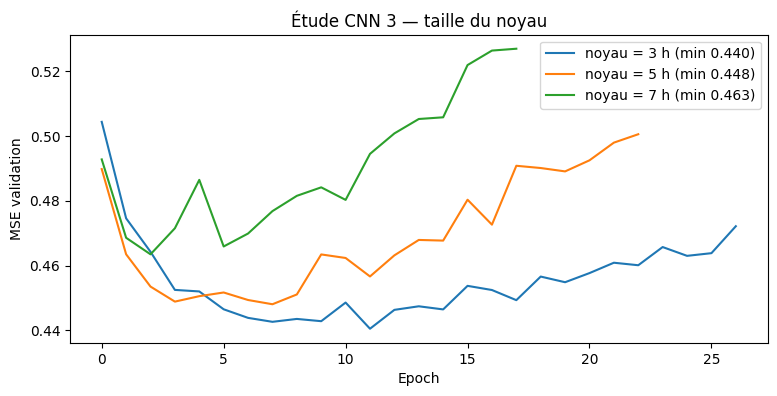

In [24]:
# Étude CNN 3 — Taille du noyau (largeur des filtres, en heures)
exp_cnn_kernel = [run_cnn_experiment(f'noyau = {k} h', kernel=k) for k in [3, 5, 7]]
plot_experiments(exp_cnn_kernel, 'Étude CNN 3 — taille du noyau')


=== dropout = 0.0 ===
Epoch   1 | train 0.8439 | val 0.5045
Epoch   2 | train 0.6507 | val 0.4710
Epoch   3 | train 0.6210 | val 0.4636
Epoch   4 | train 0.6017 | val 0.4574
Epoch   5 | train 0.5865 | val 0.4534
Epoch   6 | train 0.5736 | val 0.4450
Epoch   7 | train 0.5634 | val 0.4445
Epoch   8 | train 0.5558 | val 0.4434
Epoch   9 | train 0.5489 | val 0.4505
Epoch  10 | train 0.5421 | val 0.4462
Epoch  11 | train 0.5372 | val 0.4461
Epoch  12 | train 0.5321 | val 0.4477
Epoch  13 | train 0.5271 | val 0.4490
Epoch  14 | train 0.5225 | val 0.4494
Epoch  15 | train 0.5179 | val 0.4553
Epoch  16 | train 0.5137 | val 0.4541
Epoch  17 | train 0.5093 | val 0.4545
Epoch  18 | train 0.5052 | val 0.4643
Epoch  19 | train 0.5010 | val 0.4587
Epoch  20 | train 0.4976 | val 0.4624
Epoch  21 | train 0.4934 | val 0.4647
Epoch  22 | train 0.4900 | val 0.4731
Epoch  23 | train 0.4862 | val 0.4806
Arrêt anticipé à l'epoch 23

=== dropout = 0.3 ===
Epoch   1 | train 0.8584 | val 0.5044
Epoch   2 | tr

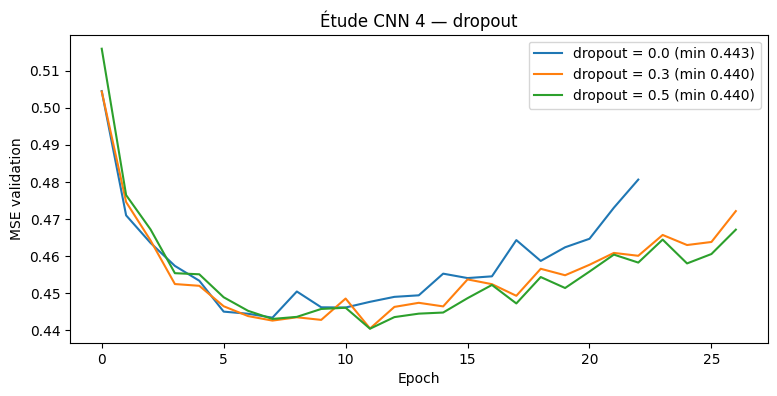

In [25]:
# Étude CNN 4 — Dropout
exp_cnn_dropout = [run_cnn_experiment(f'dropout = {d}', dropout=d) for d in [0.0, 0.3, 0.5]]
plot_experiments(exp_cnn_dropout, 'Étude CNN 4 — dropout')


=== lr = 0.001 ===
Epoch   1 | train 0.6678 | val 0.4630
Epoch   2 | train 0.5544 | val 0.4587
Epoch   3 | train 0.5154 | val 0.4805
Epoch   4 | train 0.4821 | val 0.4909
Epoch   5 | train 0.4508 | val 0.4941
Epoch   6 | train 0.4255 | val 0.5206
Epoch   7 | train 0.4015 | val 0.5324
Epoch   8 | train 0.3823 | val 0.5299
Epoch   9 | train 0.3676 | val 0.5591
Epoch  10 | train 0.3547 | val 0.5468
Epoch  11 | train 0.3449 | val 0.5519
Epoch  12 | train 0.3356 | val 0.5685
Epoch  13 | train 0.3278 | val 0.5756
Epoch  14 | train 0.3183 | val 0.5634
Epoch  15 | train 0.3131 | val 0.5897
Epoch  16 | train 0.3081 | val 0.5798
Epoch  17 | train 0.3039 | val 0.5621
Arrêt anticipé à l'epoch 17

=== lr = 0.0001 ===
Epoch   1 | train 0.8584 | val 0.5044
Epoch   2 | train 0.6646 | val 0.4746
Epoch   3 | train 0.6352 | val 0.4642
Epoch   4 | train 0.6150 | val 0.4525
Epoch   5 | train 0.5999 | val 0.4520
Epoch   6 | train 0.5874 | val 0.4465
Epoch   7 | train 0.5765 | val 0.4438
Epoch   8 | train 0

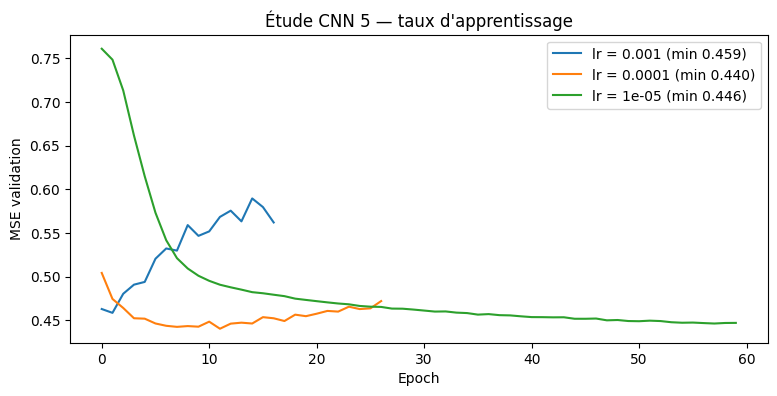

In [26]:
# Étude CNN 5 — Learning rate
exp_cnn_lr = [run_cnn_experiment(f'lr = {lr}', lr=lr) for lr in [1e-3, 1e-4, 1e-5]]
plot_experiments(exp_cnn_lr, "Étude CNN 5 — taux d'apprentissage")

Epoch   1 | train 0.7877 | val 0.4692
Epoch   2 | train 0.6244 | val 0.4487
Epoch   3 | train 0.5988 | val 0.4386
Epoch   4 | train 0.5800 | val 0.4307
Epoch   5 | train 0.5668 | val 0.4288
Epoch   6 | train 0.5554 | val 0.4268
Epoch   7 | train 0.5455 | val 0.4256
Epoch   8 | train 0.5380 | val 0.4262
Epoch   9 | train 0.5316 | val 0.4261
Epoch  10 | train 0.5241 | val 0.4312
Epoch  11 | train 0.5176 | val 0.4274
Epoch  12 | train 0.5127 | val 0.4297
Epoch  13 | train 0.5065 | val 0.4304
Epoch  14 | train 0.5015 | val 0.4328
Epoch  15 | train 0.4962 | val 0.4347
Epoch  16 | train 0.4914 | val 0.4364
Epoch  17 | train 0.4856 | val 0.4381
Epoch  18 | train 0.4813 | val 0.4405
Epoch  19 | train 0.4770 | val 0.4455
Epoch  20 | train 0.4725 | val 0.4450
Epoch  21 | train 0.4683 | val 0.4444
Epoch  22 | train 0.4637 | val 0.4474
Arrêt anticipé à l'epoch 22


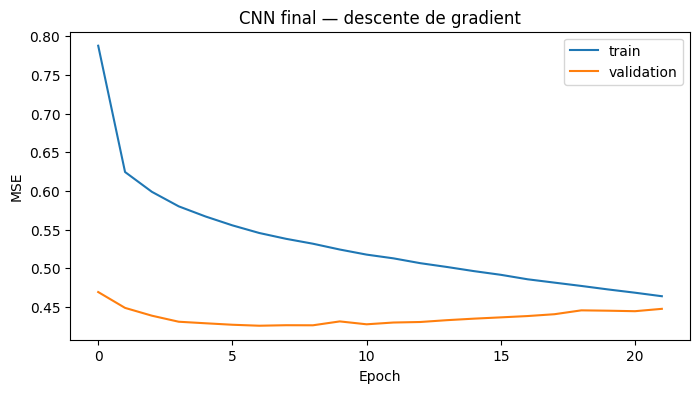

Meilleure loss val : 0.4256


In [28]:
# Modèle final : meilleurs hyperparamètres trouvés par l'étude
BEST_CNN = dict(lookback=168, channels=32, kernel=3, dropout= 0.3 , lr=1e-4,
                optimizer='adam', batch_size=64, weight_decay=1e-4)

data = get_cnn_data(BEST_CNN['lookback'])
torch.manual_seed(SEED)
tr = DataLoader(data['train'], batch_size=BEST_CNN['batch_size'], shuffle=True)
va = DataLoader(data['val'],   batch_size=64)
te = DataLoader(data['test'],  batch_size=64)

cnn_final = CNN1D(n_features, lookback=BEST_CNN['lookback'], channels=BEST_CNN['channels'],
                  kernel=BEST_CNN['kernel'], dropout=BEST_CNN['dropout']).to(device)
cnn_final, hist_cnn_final = train_model(cnn_final, tr, va, lr=BEST_CNN['lr'],
                                        optimizer_name=BEST_CNN['optimizer'],
                                        weight_decay=BEST_CNN['weight_decay'], patience=15)

plt.figure(figsize=(8, 4))
plt.plot(hist_cnn_final['train'], label='train')
plt.plot(hist_cnn_final['val'], label='validation')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend()
plt.title('CNN final — descente de gradient'); plt.show()
print(f"Meilleure loss val : {min(hist_cnn_final['val']):.4f}")